Starting evaluation pipeline...
Processing 69 match files from RF_MAPWISE_01/Inferno...

--- Computing F-1 Scores ---
Epoch   0 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.5256
Epoch  10 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.7131
Epoch  20 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.7326
Epoch  30 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.7596
Epoch  40 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.7783
Epoch  50 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.7990
Epoch  60 | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.8138
Epoch End | Total Rounds Evaluated: 1214 | F-1 Score (Macro): 0.8477


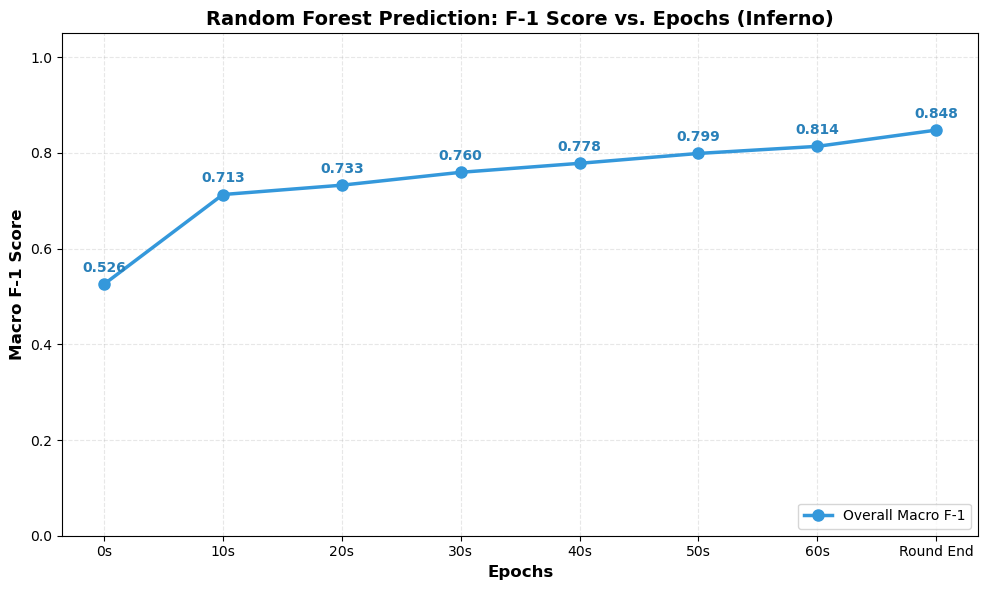

In [2]:
import polars as pl
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import f1_score

# ==========================================
# 1. CONFIGURATION & PATHS
# ==========================================
RESULTS_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\STOMs\RF_MAPWISE_01\Inferno")

# Epoch identifiers as expected in the column names (pred_epoch_i)
EPOCHS = ["0", "10", "20", "30", "40", "50", "60", "End"]

# ==========================================
# 2. DATA RETRIEVAL & METRIC COMPUTATION
# ==========================================
def compute_overall_f1_scores(results_dir):
    """
    Parses all match result CSVs, extracts predictions per epoch and the actual winners,
    and computes the overall macro F-1 score per epoch across all matches.
    """
    if not results_dir.exists():
        print(f"Error: Directory does not exist -> {results_dir}")
        return None

    csv_files = list(results_dir.glob("*.csv"))
    if not csv_files:
        print(f"No CSV files found in -> {results_dir}")
        return None

    print(f"Processing {len(csv_files)} match files from {results_dir.parent.name}/{results_dir.name}...")

    # Dictionaries to aggregate true labels and predictions for each epoch across all matches
    all_y_true = {e: [] for e in EPOCHS}
    all_y_pred = {e: [] for e in EPOCHS}

    for filepath in csv_files:
        try:
            df = pl.read_csv(filepath)
            
            # Identify the final column dynamically, or rely on "actual_winner"
            final_col_name = df.columns[-1] 
            
            # Filter out any invalid labels to ensure clean evaluation
            df_valid = df.filter(pl.col(final_col_name).is_in(["CT", "T"]))
            
            if df_valid.is_empty():
                continue
                
            actual_winners = df_valid[final_col_name].to_list()
            
            # Extract predictions for each epoch
            for e in EPOCHS:
                pred_col = f"pred_epoch_{e}"
                
                if pred_col in df_valid.columns:
                    predictions = df_valid[pred_col].to_list()
                    all_y_pred[e].extend(predictions)
                    all_y_true[e].extend(actual_winners)
                else:
                    print(f"Warning: Column {pred_col} not found in {filepath.name}")
                    
        except Exception as ex:
            print(f"Error processing {filepath.name}: {ex}")

    # Compute F-1 scores
    f1_scores = []
    print(f"\n--- Computing F-1 Scores ---")
    
    for e in EPOCHS:
        if all_y_true[e] and all_y_pred[e]:
            # Macro average treats both CT and T classes equally
            f1 = f1_score(all_y_true[e], all_y_pred[e], average="macro")
            f1_scores.append(f1)
            print(f"Epoch {e:>3} | Total Rounds Evaluated: {len(all_y_true[e])} | F-1 Score (Macro): {f1:.4f}")
        else:
            f1_scores.append(0.0)
            print(f"Epoch {e:>3} | No valid data available")

    return f1_scores

# ==========================================
# 3. VISUALIZATION
# ==========================================
def plot_f1_vs_epochs(f1_scores):
    """Generates a line plot for F-1 score vs. epochs."""
    if not f1_scores:
        print("No F-1 scores to plot.")
        return

    plt.figure(figsize=(10, 6))
    
    # Format x-axis labels for readability
    x_labels = [f"{e}s" if e != "End" else "Round End" for e in EPOCHS]
    
    # Plotting the F-1 score curve
    plt.plot(x_labels, f1_scores, marker='o', markersize=8, color="#3498db", linewidth=2.5, label="Overall Macro F-1")
    
    # Formatting the plot
    plt.title("Random Forest Prediction: F-1 Score vs. Epochs (Inferno)", fontsize=14, fontweight='bold')
    plt.xlabel("Epochs", fontsize=12, fontweight='bold')
    plt.ylabel("Macro F-1 Score", fontsize=12, fontweight='bold')
    
    # Set y-axis limits (0.0 to 1.05 provides slight headroom above perfect score)
    plt.ylim(0.0, 1.05)
    
    # Add data value labels directly to the points
    for i, f1 in enumerate(f1_scores):
        plt.text(i, f1 + 0.02, f"{f1:.3f}", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#2980b9")

    plt.grid(True, alpha=0.3, linestyle='--')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    print("Starting evaluation pipeline...")
    
    # Compute the scores from the results directory
    overall_f1_scores = compute_overall_f1_scores(RESULTS_DIR)
    
    # Generate the visualization
    if overall_f1_scores:
        plot_f1_vs_epochs(overall_f1_scores)
    else:
        print("Pipeline finished, but no data was processed.")